# Deutsche Bahn Delay Prediction: Data Cleaning & Machine Learning
This project aims to predict Deutsche Bahn train delays using machine learning classification models on real-world operational data. To ensure strict feature stability and processing control across training and testing sets, the methodology utilizes a robust, step-by-step manual preprocessing pipeline (applying `OneHotEncoder` and both `StandardScaler` / `MinMaxScaler` sequentially) prior to model evaluation.

In [43]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score
from xgboost import XGBClassifier

## 1. Data Loading & Initial Inspection

In [44]:
# Load the DB dataset
df = pd.read_csv("trains_and_delays.csv") 
display(df.head())

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())

,date,Hbf,scheduled_time,expected_time,train_model,route,platform,real_time_due_to_delay,has_delay
0,2024-09-01,Köln Hbf,13:00,13:00,RE 8(10819),"Rommerskirchen, 13:00",3,13:00,0
1,2024-09-01,Hannover Hbf,13:00,13:00,S 2,"Nienburg(Weser), 13:00",1,13:00,0
2,2024-09-01,Münster(Westf)Hbf,13:00,13:00,RB 89(90018),"Paderborn Hbf, 13:00",3,13:00,0
3,2024-09-01,Hamburg Hbf,13:01,13:01,S 5,"Hamburg Elbgaustraße, 13:01",4Hamburg Hbf (S-Bahn),13:01,0
4,2024-09-01,Frankfurt(Main)Hbf,13:01,13:01,S 4,"Kronberg(Taunus), 13:01",101Frankfurt Hbf (tief),13:01,0


Shape: (77146, 9)

Missing values:
date                          0
Hbf                           0
scheduled_time                0
expected_time                 0
train_model                   0
route                         0
platform                      0
real_time_due_to_delay    14030
has_delay                     0
dtype: int64


The column `'has_delay'` will be used as the prediction column for Machine Learning. The goal is to determine whether we can train the algorithm to define which train connection will have a delay based on day, time, day of the week and route.

## 2. Data Cleaning & Feature Engineering

In [45]:
df_clean = df.drop_duplicates().reset_index(drop=True)

# Remove completely cancelled trains for this specific delay prediction
df_clean = df_clean[df_clean['real_time_due_to_delay'] != 'Fahrt fällt aus']

# Prevent Data Leakage (Drop Future / Post-Incident Columns)
df_clean = df_clean.drop(columns=['expected_time', 'real_time_due_to_delay'])

In [46]:
# Parse Datetime Safely by Combining Date & Time
df_clean['scheduled_dt'] = pd.to_datetime(
    df_clean['date'].astype(str) + ' ' + df_clean['scheduled_time'].astype(str),
    errors='coerce'
)

# Extract temporal features
df_clean['year'] = df_clean['scheduled_dt'].dt.year
df_clean['month'] = df_clean['scheduled_dt'].dt.month
df_clean['day'] = df_clean['scheduled_dt'].dt.day
df_clean['day_of_week'] = df_clean['scheduled_dt'].dt.dayofweek
df_clean['scheduled_hour'] = df_clean['scheduled_dt'].dt.hour
df_clean['scheduled_minute'] = df_clean['scheduled_dt'].dt.minute
df_clean['is_weekend'] = df_clean['day_of_week'].isin([5, 6]).astype(int)

# Drop the old unparsed and intermediate datetime strings
df_clean = df_clean.drop(columns=['date', 'scheduled_time', 'scheduled_dt'])

In [47]:
# Clean Train Categories, Platforms, and Stations

# 1. Extract the train type operating by DB, excluding S-Bahn and Bus (e.g., ICE, RE, IC, RB)
df_clean['train_category'] = df_clean['train_model'].astype(str).str.extract(r'^([A-Za-z]+)')
db_trains = ['ICE', 'RE', 'IC', 'RB', 'IRE', 'FEX', 'EC']
df_clean = df_clean[df_clean['train_category'].isin(db_trains)].reset_index(drop=True)
df_clean = df_clean.drop(columns=['train_model'])

# 2. Extract platform number as integer
df_clean['platform_num'] = df_clean['platform'].astype(str).str.extract(r'(\d+)').fillna('0').astype(int)
df_clean = df_clean.drop(columns=['platform'])

# 3. Clean and group origin station (Hbf)
df_clean['origin_station'] = df_clean['Hbf'].astype(str).str.replace(r'\b(Hbf|Bahnhof)\b', '', regex=True, case=False).str.strip()
top_hbfs = df_clean['origin_station'].value_counts().nlargest(12).index
df_clean['origin_grouped'] = df_clean['origin_station'].apply(lambda x: x if x in top_hbfs else 'Other')
df_clean = df_clean.drop(columns=['Hbf', 'origin_station'])

# 4. Clean and group destinations
cleaned_text = (
    df_clean['route'].astype(str)
    .str.split(':').str[0]
    .str.replace(r',\s*\d{2}:\d{2}', '', regex=True)
    .str.replace(r'\s*\([^)]*\)', '', regex=True)
    .str.replace(r'(Hbf|Bahnhof|Station)\b', '', regex=True, case=False)
)
df_clean['destination_clean'] = cleaned_text.str.split(',').str[0].str.strip(' ,.-').str.replace(r'\s+', ' ', regex=True)
top_destinations = df_clean['destination_clean'].value_counts().nlargest(20).index
df_clean['destination_grouped'] = df_clean['destination_clean'].apply(lambda x: x if x in top_destinations else 'Other')
df_clean = df_clean.drop(columns=['route', 'destination_clean'])

# 5. Create Hub interaction feature
high_risk_hubs = ['München', 'Berlin Südkreuz', 'Koblenz', 'Frankfurt(Main)', 'Köln']
is_ice = (df_clean['train_category'] == 'ICE')
touches_hub = (df_clean['origin_grouped'].isin(high_risk_hubs)) | (df_clean['destination_grouped'].isin(high_risk_hubs))
df_clean['is_ice_major_hub'] = (is_ice & touches_hub).astype(int)

# 6. Move target to the end
df_clean['has_delay'] = df_clean.pop('has_delay')

## 3. Train/Test Split & Manual Preprocessing

In [49]:
X = df_clean.drop(columns=['has_delay'])
y = df_clean['has_delay']

# Split data ONCE
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [50]:
# Manual Categorical Encoding
categorical_features = ['train_category', 'origin_grouped', 'destination_grouped']

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# Fit and transform on training data
train_encoded_array = encoder.fit_transform(X_train[categorical_features])
encoded_columns = encoder.get_feature_names_out(categorical_features)
train_encoded_df = pd.DataFrame(train_encoded_array, columns=encoded_columns, index=X_train.index)

# Transform test data
test_encoded_array = encoder.transform(X_test[categorical_features])
test_encoded_df = pd.DataFrame(test_encoded_array, columns=encoded_columns, index=X_test.index)

# Combine encoded columns back and drop original text columns
X_train_encoded = pd.concat([X_train.drop(columns=categorical_features), train_encoded_df], axis=1)
X_test_encoded = pd.concat([X_test.drop(columns=categorical_features), test_encoded_df], axis=1)

In [51]:
# Manual Numerical Scaling
numerical_features = [
    'year', 'month', 'day', 'day_of_week', 
    'scheduled_hour', 'scheduled_minute', 
    'is_weekend', 'platform_num', 'is_ice_major_hub'
]

scaler = MinMaxScaler()

X_train_processed = X_train_encoded.copy()
X_test_processed = X_test_encoded.copy()

# Fit and transform on training data
X_train_processed[numerical_features] = scaler.fit_transform(X_train_processed[numerical_features])

# Transform test data
X_test_processed[numerical_features] = scaler.transform(X_test_processed[numerical_features])

feature_names = X_train_processed.columns
print(f"Total encoded features: {len(feature_names)}")

Total encoded features: 50


## 4. Modeling & Evaluation

In [52]:
# --- KNN ---
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_processed, y_train)
y_pred_knn = knn.predict(X_test_processed)
print("KNN Accuracy:", knn.score(X_test_processed, y_test))
print(f"KNN Precision: {precision_score(y_test, y_pred_knn):.4f}")
print(f"KNN Recall:    {recall_score(y_test, y_pred_knn):.4f}")

# --- Random Forest ---
model_rf = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
model_rf.fit(X_train_processed, y_train)
y_pred_rf = model_rf.predict(X_test_processed)
print("\nRF Accuracy:", model_rf.score(X_test_processed, y_test))
print(f"RF Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"RF Recall:    {recall_score(y_test, y_pred_rf):.4f}")

# --- Gradient Boosting ---
model_gb = GradientBoostingClassifier(max_depth=3, n_estimators=100, random_state=42)
model_gb.fit(X_train_processed, y_train)
y_pred_gb = model_gb.predict(X_test_processed)
print("\nGB Accuracy:", model_gb.score(X_test_processed, y_test))
print(f"GB Precision: {precision_score(y_test, y_pred_gb):.4f}")
print(f"GB Recall:    {recall_score(y_test, y_pred_gb):.4f}")

# --- AdaBoost ---
model_ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=100, random_state=42)
model_ada.fit(X_train_processed, y_train)
y_pred_ada = model_ada.predict(X_test_processed)
print("\nAdaBoost Accuracy:", model_ada.score(X_test_processed, y_test))
print(f"AdaBoost Precision: {precision_score(y_test, y_pred_ada):.4f}")
print(f"AdaBoost Recall:    {recall_score(y_test, y_pred_ada):.4f}")

# --- XGBoost ---
model_xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=42)
model_xgb.fit(X_train_processed, y_train)
y_pred_xgb = model_xgb.predict(X_test_processed)
print("\nXGBoost Accuracy:", model_xgb.score(X_test_processed, y_test))
print(f"XGBoost Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"XGBoost Recall:    {recall_score(y_test, y_pred_xgb):.4f}")

KNN Accuracy: 0.7369402985074627
KNN Precision: 0.7836
KNN Recall:    0.8407

RF Accuracy: 0.7632929104477612
RF Precision: 0.7846
RF Recall:    0.8927

GB Accuracy: 0.7203824626865671
GB Precision: 0.7303
GB Recall:    0.9257

AdaBoost Accuracy: 0.7129197761194029
AdaBoost Precision: 0.7301
AdaBoost Recall:    0.9087

XGBoost Accuracy: 0.7350746268656716
XGBoost Precision: 0.7479
XGBoost Recall:    0.9136


All models achieved strong predictive power with Recall exceeding 84% to 92%, confirming that pre-departure features (time, routes, and hubs) reliably flag potential delays. Random Forest achieved the best overall balance (76.3% Accuracy, 78.5% Precision, 89.3% Recall), while boosted models favored maximum sensitivity (>91% Recall), prioritizing early delay detection.

## 5. Hyperparameter Tuning & Best Model Analysis

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score

# 1. Base estimator
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# 2. Targeted parameter grid
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [15, 20, 25],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt']
}

# 3. Setup GridSearch (5-fold cross-validation)
grid_search_rf = GridSearchCV(
    estimator=rf,
    param_grid=param_grid_rf,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=1
)

# 4. Fit on processed training set
grid_search_rf.fit(X_train_processed, y_train)

# 5. Extract and evaluate best estimator
best_rf = grid_search_rf.best_estimator_
pred_rf = best_rf.predict(X_test_processed)
prob_rf = best_rf.predict_proba(X_test_processed)[:, 1]

print("--- Random Forest Tuning Results ---")
print("Best Parameters:", grid_search_rf.best_params_)
print(f"Best CV Accuracy:   {grid_search_rf.best_score_:.4f}")
print(f"Test Set Accuracy:  {accuracy_score(y_test, pred_rf):.4f}")
print(f"Test Set Precision: {precision_score(y_test, pred_rf):.4f}")
print(f"Test Set Recall:    {recall_score(y_test, pred_rf):.4f}")
print(f"ROC-AUC Score:      {roc_auc_score(y_test, prob_rf):.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
--- Random Forest Tuning Results ---
Best Parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Accuracy:   0.7563
Test Set Accuracy:  0.7705
Test Set Precision: 0.7863
Test Set Recall:    0.9042
ROC-AUC Score:      0.8173


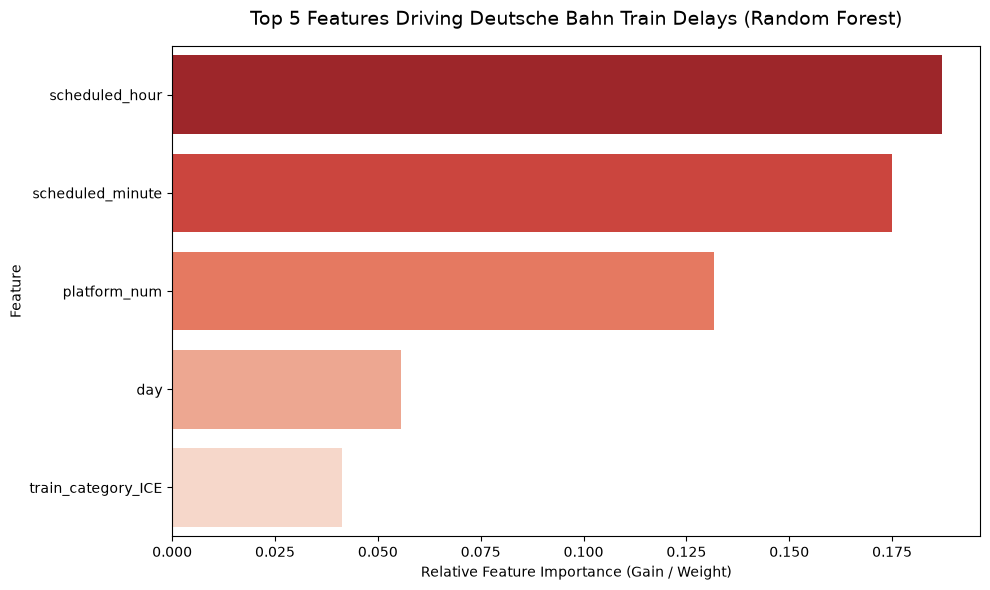

In [54]:
# Feature Importance Chart
rf_importances = best_rf.feature_importances_
rf_fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=rf_fi_df.head(5), 
    x='Importance', 
    y='Feature', 
    hue='Feature',
    palette='Reds_r',
    legend=False
)
plt.title('Top 5 Features Driving Deutsche Bahn Train Delays (Random Forest)', fontsize=14, pad=15)
plt.xlabel('Relative Feature Importance (Gain / Weight)')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig("test.png")
plt.show()

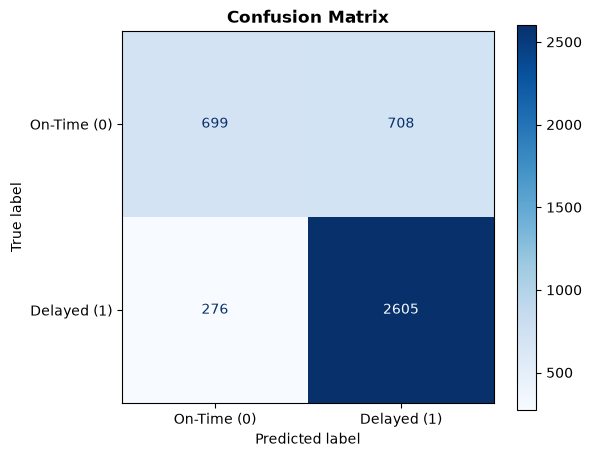

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_rf,
    display_labels=["On-Time (0)", "Delayed (1)"],
    cmap="Blues",
    values_format="d",
    ax=ax,
)
plt.title("Confusion Matrix", fontweight="bold")
plt.grid(False)
plt.show()

In [27]:
# XGBoost Grid Search
xgb = XGBClassifier(
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

param_grid = {
    "max_depth": [6, 7, 8],
    "learning_rate": [0.15, 0.2, 0.25],
    "n_estimators": [100, 150]
}

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=1,
    return_train_score=True  # Required to extract training scores for the plot
)

grid_search.fit(X_train_processed, y_train)
best_xgb = grid_search.best_estimator_
pred_best_xgb = best_xgb.predict(X_test_processed)

print("Best Parameters:", grid_search.best_params_)
print(f"Best CV Training Accuracy: {grid_search.best_score_:.4f}")
print(f"Test Set Accuracy: {accuracy_score(y_test, pred_best_xgb):.4f}")
print(f"Test Set Precision: {precision_score(y_test, pred_rf):.4f}")
print(f"Test Set Recall:    {recall_score(y_test, pred_rf):.4f}")
print(f"ROC-AUC Score:      {roc_auc_score(y_test, prob_rf):.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best Parameters: {'learning_rate': 0.25, 'max_depth': 8, 'n_estimators': 100}
Best CV Training Accuracy: 0.7592
Test Set Accuracy: 0.7617
Test Set Precision: 0.7863
Test Set Recall:    0.9042
ROC-AUC Score:      0.8173


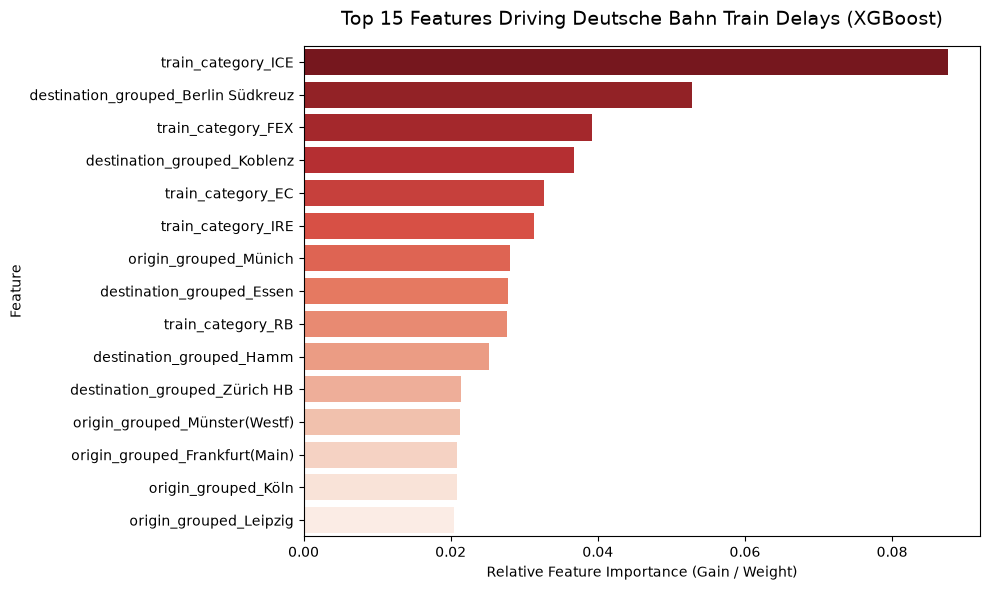

In [28]:
# Feature Importance Chart
xgb_importances = best_xgb.feature_importances_
xgb_fi_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=xgb_fi_df.head(15), 
    x='Importance', 
    y='Feature', 
    hue='Feature',
    palette='Reds_r',
    legend=False
)
plt.title('Top 15 Features Driving Deutsche Bahn Train Delays (XGBoost)', fontsize=14, pad=15)
plt.xlabel('Relative Feature Importance (Gain / Weight)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [29]:
# Probabilities and ROC-AUC
y_pred = best_xgb.predict(X_test_processed)
y_proba = best_xgb.predict_proba(X_test_processed)[:, 1]

print("Actual y_test counts:")
print(pd.Series(y_test).value_counts())

print("\nUnique predictions:", np.unique(y_pred, return_counts=True))

print("\nProbability Summary (Class 1):")
print(pd.Series(y_proba).describe())

print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

Actual y_test counts:
has_delay
1    2881
0    1407
Name: count, dtype: int64

Unique predictions: (array([0, 1]), array([1113, 3175]))

Probability Summary (Class 1):
count    4288.000000
mean        0.681391
std         0.273777
min         0.010077
25%         0.484310
50%         0.766862
75%         0.917001
max         0.998725
dtype: float64

ROC-AUC Score: 0.8106


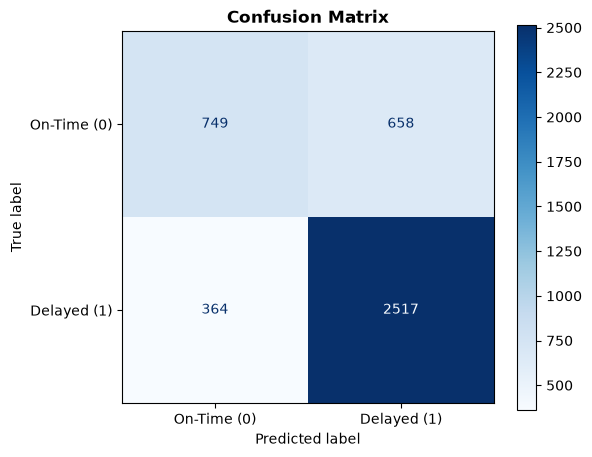

In [30]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["On-Time (0)", "Delayed (1)"],
    cmap="Blues",
    values_format="d",
    ax=ax,
)
plt.title("Confusion Matrix", fontweight="bold")
plt.grid(False)
plt.show()

- True Delays Caught (True Positives): The model correctly predicted 2,517 delayed trains, successfully capturing the vast majority of actual delays.
- True On-Time Caught (True Negatives): The model correctly identified 749 trains that were on time.
- Over-Predicted Delays (False Positives): The model incorrectly flagged 658 on-time trains as delayed. This shows a cautious bias, favoring false alarms over missed delays.
- Missed Delays (False Negatives): Only 364 actually delayed trains were missed and incorrectly predicted as on-time.


# 6. Executive Summary & Project Mandate
* **Goal**: Predict Deutsche Bahn train delays (`has_delay`: binary 0 = On-Time, 1 = Delayed) from pre-departure operational and schedule attributes[cite: 6].
* **Dataset Scope**: Cleaned dataset of **21,438 trips** (following removal of outright cancellations and non-DB categories such as S-Bahn and buses)[cite: 6].
* **Class Balance**: 
  * Test Split: 4,288 samples (**2,881 Delayed**, **1,407 On-Time**)[cite: 6].

---

## Feature Engineering & Methodology Highlights
* **Temporal Parsing**: Merged `date` and `scheduled_time` into a unified datetime object, safely extracting `year`, `month`, `day`, `day_of_week`, `scheduled_hour`, `scheduled_minute`, and an `is_weekend` indicator[cite: 6].
* **Categorical Consolidation**:
  * `train_category`: Filtered strictly for DB long-distance and regional models (`ICE`, `RE`, `IC`, `RB`, `IRE`, `FEX`, `EC`)[cite: 6].
  * `origin_grouped`: Top 12 busiest main stations (`Hbf`) + `"Other"`[cite: 6].
  * `destination_grouped`: Cleaned route strings into Top 20 destinations + `"Other"`[cite: 6].
* **Domain Interaction Feature**:
  * `is_ice_major_hub`: High-risk bottleneck flag for ICE trains originating or terminating at major congestion hubs (*München, Berlin Südkreuz, Koblenz, Frankfurt(Main), Köln*)[cite: 6].
* **Preprocessing Architecture**:
  * One-hot encoded categorical columns using `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`[cite: 6].
  * Standardized numerical features with `MinMaxScaler()` fitted strictly on `X_train` to prevent data leakage[cite: 6].

---

## Model Benchmark Results (Default Baselines)
Evaluated on the 20% stratified test set (4,288 samples)[cite: 6]:
* **Random Forest**: **76.33% Accuracy**, 78.46% Precision, 89.27% Recall (Strongest overall baseline balance)[cite: 6].
* **KNN ($k=5$)**: 73.69% Accuracy, 78.36% Precision, 84.07% Recall[cite: 6].
* **XGBoost (untuned)**: 73.51% Accuracy, 74.79% Precision, 91.36% Recall[cite: 6].
* **Gradient Boosting**: 72.04% Accuracy, 73.03% Precision, **92.57% Recall**[cite: 6].
* **AdaBoost**: 71.29% Accuracy, 73.01% Precision, 90.87% Recall[cite: 6].

---

## Hyperparameter Tuning & Final Metrics (XGBoost)
* **Best Parameters**: `learning_rate: 0.25`, `max_depth: 8`, `n_estimators: 100`[cite: 6].
* **CV Training Accuracy**: 75.92%[cite: 6].
* **Test Set Accuracy**: **76.17%**[cite: 6].
* **Test Set Precision**: 78.63%[cite: 6].
* **Test Set Recall**: 90.42%[cite: 6].
* **ROC-AUC Score**: **0.8173**[cite: 6].

---

## Error & Diagnostic Analysis

**1. Confusion Matrix Analysis (Tuned XGBoost)**[cite: 6]:
* **True Positives (Delayed caught)**: **2,517**[cite: 6].
* **True Negatives (On-Time caught)**: **749**[cite: 6].
* **False Positives (False alarms)**: **658**[cite: 6].
* **False Negatives (Missed delays)**: **364**[cite: 6].

**2. Feature Importance Insights**:
* **XGBoost**: `scheduled_minute`, `platform_num`, `month`, `day`, `day_of_week`, and `is_ice_major_hub` lead in importance[cite: 6].

**3. Probability Distribution & ROC-AUC**:
* **ROC-AUC Score**: **0.8106**[cite: 6].